In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

### Criação do nosso dataset

In [57]:
# Definir semente pra garantir os mesmos dados aleatórios 
np.random.seed(42)

In [58]:
# 1- ABA: Funcionários (com nulos e decimais para tratamento)
dados_funcionarios = {
  'id_emp': list(range(101,131)),
  'nome': [ 'Ana Silva', 'Bruno Costa', 'Carlos Oliveira', 'Daniela Souza',
            'Eduardo Lima', 'Fernanda Alves', 'Gabriel Rocha', 'Helena Martins',
            'Igor Pereira', 'Juliana Ramos', 'Lucas Mendes', 'Mariana Castro',
            'Natan Ribeiro', 'Olivia Fernandes', 'Paulo Santos', 'Rafaela Dias',
            'Sergio Farias', 'Tatiana Gomes', 'Ubiratan Melo', 'Vanessa Cardoso',
            'Wagner Neves', 'Xavier Araujo', 'Yasmin Barbosa', 'Zeca Pagodinho',
            'Aline Duarte', 'Bernardo Cruz', 'Camila Freitas', 'Diego Machado',
            'Elisa Nogueira', 'Fabio Junior' ],
   'idade': [
     
     28.5, 34.0, np.nan, 42.3, 29.0, 31.8, 45.0, 26.0,
     np.nan, 38.2, 50.0, 23.5, 33.0, 29.7, np.nan, 41.0,
     36.4, 27.0, 48.1, 30.0, 55.0, 24.2, np.nan, 62.0, 22.8,
     37.0, 32.1, 40.0, 28.0, 46.5
   ],

  'salario': [

    4500.0, 6200.0, 5100.0, 8500.0, np.nan,
    5800.0, 9200.0, 4100.0, 4800.0, 7300.0,
    10500.0, 3900.0, 6000.0, 5400.0, 7100.0,
    8800.0, np.nan, 4300.0, 9700.0, 5600.0,
    11000.0, 4000.0, 5200.0, 12500.0, np.nan,
    6900.0, 5900.0, 8100.0, 4700.0, 9400.0
  ],
    'departamento': [

    'Vendas', 'TI', 'RH', 'TI', 'Vendas',
    'Marketing', 'TI', 'RH', 'Marketing',
    'Vendas', 'Diretoria', 'RH', 'TI',
    'Vendas', 'Marketing', 'TI', 'Vendas',
    'RH', 'Diretoria', 'Marketing', 'Diretoria',
    'Vendas', 'TI', 'Diretoria', 'RH', 'Vendas',
    'Marketing', 'TI', 'RH', 'Vendas'
  ],
  'ativo': [

    True, True, True, True, False,
    True, True, True, False, True,
    True, True, True, True, True, True,
    False, True, True, True, True, True, False,
    True, True, True, True, True, True, False

  ],

  'id_dept' : [ 
    1, 2, 3, 2, 1,
    4, 2, 3, 4, 1, 5,
    3, 2, 1, 4, 2, 1,
    3, 5, 4, 5, 1, 2,
    5, 3, 1, 4, 2,
    3, 1
  ]}

In [59]:
# 2. ABA: Departamentos (para cruazamento com .merge())
dados_departamentos = {
  'id_dept': [1, 2, 3, 4, 5, 6],
    'nome_dept': ['Vendas', 'TI', 'RH', 'Marketing', 'Diretoria', 'Logística'],
      'orcamento_anual': [150000, 300000, 100000, 200000, 500000, 120000]
}

In [60]:
# 3. ABA: Série Temporal de Ações (para .diff() e gráficos)
datas = pd.date_range(start='2025-01-01', periods=30, freq='D')
df_acoes = pd.DataFrame({
  'data': datas,
    'PETR4': np.round(30.0 + np.cumsum(np.random.randn(30) * 0.5), 2),
      'ITUB4': np.round(25.0 + np.cumsum(np.random.randn(30) * 0.4), 2)
})

In [61]:
# Exportação para o arquivo excel (.xlsx) com multiplas abas
with pd.ExcelWriter('dados_departamentos.xlsx', engine='openpyxl') as writer:
  pd.DataFrame(dados_funcionarios).to_excel(writer,sheet_name='funcionarios', index=False)
  pd.DataFrame(dados_departamentos).to_excel(writer,sheet_name='departamentos', index=False)
  df_acoes.to_excel(writer, sheet_name='acoes_bolsa', index=False)

print('Tabela "dados_departamentos.xlsx" criada com sucess!!')

Tabela "dados_departamentos.xlsx" criada com sucess!!


In [62]:
import matplotlib as plt

In [63]:
# 1 - Leitura das abas
df_func = pd.read_excel('dados_departamentos.xlsx', sheet_name='funcionarios')
df_dept = pd.read_excel('dados_departamentos.xlsx', sheet_name='departamentos')
df_acoes = pd.read_excel('dados_departamentos.xlsx', sheet_name='acoes_bolsa')

In [64]:
# 2 -Inspeção e diagnóstico
print(20*'_'+' INFO '+20*'_')
print()
print(f'\nDataframe Funcionario {df_func.info()}')
print('\n--- Resumo Estatístico ---')
print(df_func.describe())

____________________ INFO ____________________

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_emp        30 non-null     int64  
 1   nome          30 non-null     object 
 2   idade         26 non-null     float64
 3   salario       27 non-null     float64
 4   departamento  30 non-null     object 
 5   ativo         30 non-null     bool   
 6   id_dept       30 non-null     int64  
dtypes: bool(1), float64(2), int64(2), object(2)
memory usage: 1.6+ KB

Dataframe Funcionario None

--- Resumo Estatístico ---
           id_emp      idade       salario    id_dept
count   30.000000  26.000000     27.000000  30.000000
mean   115.500000  36.196154   6833.333333   2.666667
std      8.803408  10.193860   2392.295325   1.397864
min    101.000000  22.800000   3900.000000   1.000000
25%    108.250000  28.625000   4950.000000   1.250000
50%    115.5

### TRATAMENTO DE INCONSISTÊNCIAS E NULOS

In [65]:
# Calculando a média na coluna idade
media_idade = df_func['idade'].mean()

#Preenchendo os valores ausentes (NaN) com a média calculada
df_func['idade'] = df_func['idade'].fillna(media_idade)

df_func.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_emp        30 non-null     int64  
 1   nome          30 non-null     object 
 2   idade         30 non-null     float64
 3   salario       27 non-null     float64
 4   departamento  30 non-null     object 
 5   ativo         30 non-null     bool   
 6   id_dept       30 non-null     int64  
dtypes: bool(1), float64(2), int64(2), object(2)
memory usage: 1.6+ KB


### Transformado a coluna idade em int

In [66]:
df_func['idade'] = df_func['idade'].round().astype(int)

df_func.dtypes['idade']


dtype('int64')

In [67]:
# Calculando a média da coluna salário
mediana_salario = df_func['salario'].median()

#Preencher com a média os valores faltantes da coluna salário
df_func['salario'] = df_func['salario'].fillna(mediana_salario)

df_func.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_emp        30 non-null     int64  
 1   nome          30 non-null     object 
 2   idade         30 non-null     int64  
 3   salario       30 non-null     float64
 4   departamento  30 non-null     object 
 5   ativo         30 non-null     bool   
 6   id_dept       30 non-null     int64  
dtypes: bool(1), float64(1), int64(3), object(2)
memory usage: 1.6+ KB


### Criando colunas calculadas

In [68]:
# total de valores recebidos por funcionário no ano
df_func['salario_anual'] = df_func['salario'] * 12

# Criando categorias de salários
df_func['filtro_TI_alto'] = (df_func['departamento'] == 'TI') & (df_func['salario'] >6000)

print('\n--- FUNCIONÁROS TI > 6K ---')

df_func[['nome','filtro_TI_alto','salario']]



--- FUNCIONÁROS TI > 6K ---


,nome,filtro_TI_alto,salario
0,Ana Silva,False,4500.0
1,Bruno Costa,True,6200.0
2,Carlos Oliveira,False,5100.0
3,Daniela Souza,True,8500.0
4,Eduardo Lima,False,6000.0
5,Fernanda Alves,False,5800.0
6,Gabriel Rocha,True,9200.0
7,Helena Martins,False,4100.0
8,Igor Pereira,False,4800.0
9,Juliana Ramos,False,7300.0


### Agrupamento Complexo com AGG

In [69]:
relatorio_setores = df_func.groupby('departamento').agg(
  total_func = ('id_emp', 'count'),
  idade_media = ('idade', 'mean'),
  salario_medio = ('salario', 'mean'),
  salario_max = ('salario', 'max')
).sort_values(by='salario_medio', ascending=False)

print('\n--- RELATÓRIO POR DEPARTAMENTO ---')
print(relatorio_setores)


--- RELATÓRIO POR DEPARTAMENTO ---
              total_func  idade_media  salario_medio  salario_max
departamento                                                     
Diretoria              4    53.750000   10925.000000      12500.0
TI                     7    38.714286    7428.571429       9200.0
Vendas                 8    33.500000    6187.500000       9400.0
Marketing              5    33.200000    5840.000000       7100.0
RH                     6    27.333333    4683.333333       6000.0


### Cruzamento de Tabelas

In [70]:
df_completo = pd.merge(df_func, df_dept, on='id_dept', how='left')
print('\n--- PRIMEIROS REGISTROS APÓS O MERGE ---')
print(df_completo[['nome', 'departamento', 'orcamento_anual']].head())


--- PRIMEIROS REGISTROS APÓS O MERGE ---
              nome departamento  orcamento_anual
0        Ana Silva       Vendas           150000
1      Bruno Costa           TI           300000
2  Carlos Oliveira           RH           100000
3    Daniela Souza           TI           300000
4     Eduardo Lima       Vendas           150000


SÉRIES TEMPORAIS E VARIAÇÃO COM DIFF( )

In [71]:
df_acoes['var_PETR4'] = df_acoes['PETR4'].diff()

##### VISUALIZAÇÃO COM MATPLOTLIB (SUBPLOTS)

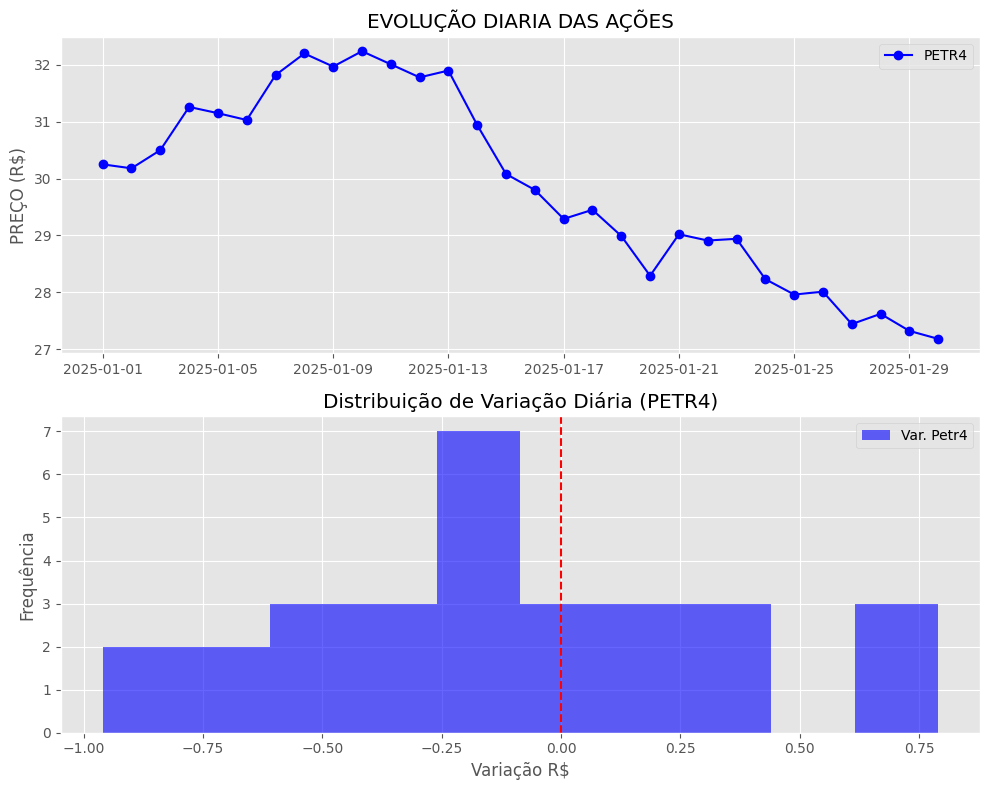

In [72]:
import matplotlib.pyplot as plt

# Configurando o Tema
plt.style.use('ggplot')

# Criar a figura e os eixos juntos
fig, (ax1, ax2) = plt.subplots(nrows= 2, ncols=1, figsize=(10, 8))

# Linha de Evolução (Eixo X =  Data)
ax1.plot(df_acoes['data'], df_acoes['PETR4'], label='PETR4', color='blue', marker='o')
ax1.set_title('EVOLUÇÃO DIARIA DAS AÇÕES')
ax1.set_ylabel('PREÇO (R$)')
ax1.legend()

# Histograma da Variação (Eixo X = Variação em Reais)
ax2.hist(df_acoes['var_PETR4'].dropna(), bins=10, color='blue', alpha=0.6, label='Var. Petr4')
ax2.set_title('Distribuição de Variação Diária (PETR4)')
ax2.set_xlabel('Variação R$')
ax2.set_ylabel('Frequência')
ax2.axvline(0, color='red', linestyle='--')
ax2.legend()

# Ajustar espaçamento e RENDERIZAR
fig.tight_layout()
plt.show()

In [73]:
# Salvando todo o tratamento no arquivo local (vscode)
with pd.ExcelWriter('dados_departamentos.xlsx', engine='openpyxl') as writer:
  df_func.to_excel(writer, sheet_name='funcionarios', index=False)
  df_dept.to_excel(writer, sheet_name='departamentos', index=False)
  df_acoes.to_excel(writer, sheet_name='acoes_bolsa', index=False)

print('Planilha atualizada com sucesso!!')

Planilha atualizada com sucesso!!


#### Contagem de Funcionários por Setor (plt.pie)

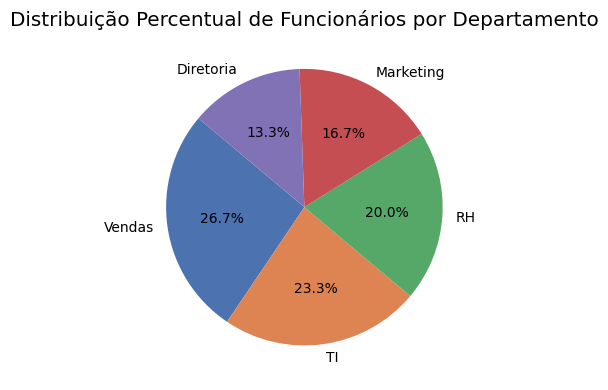

In [74]:
# Contagem de funcionários por setor
contagem_setores = df_func['departamento'].value_counts()

plt.figure(figsize=(6,4))
plt.style.use('ggplot')

plt.pie(
  contagem_setores.values,
  labels= contagem_setores.index,
  autopct='%1.1f%%', # Exibe a porcentagem com 1 casa decimal
  startangle=140,    # Ângulo inicial da rotação
  colors= ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B6']
)

plt.title('Distribuição Percentual de Funcionários por Departamento')
plt.tight_layout()
plt.show()

#### Comparativo de Salário Médio (plt.barh)

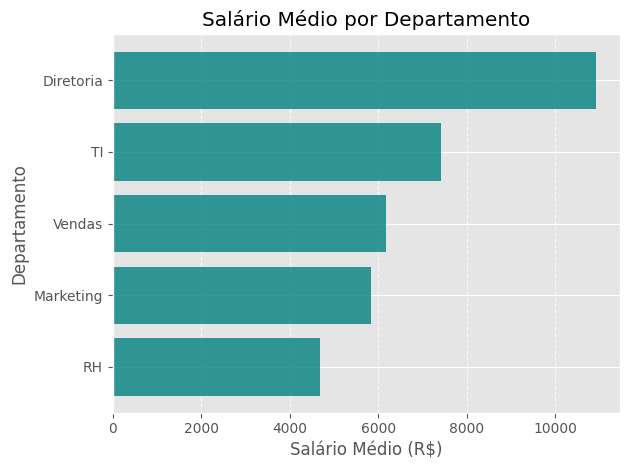

In [75]:
# Média salarial por departamento (ordenada)
media_salarial = df_func.groupby('departamento')['salario'].mean().sort_values(ascending=True)


plt.Figure(figsize=(10,5))

plt.barh(media_salarial.index, media_salarial.values, color='teal', alpha=0.8)

plt.title('Salário Médio por Departamento')
plt.xlabel('Salário Médio (R$)')
plt.ylabel('Departamento')
plt.grid(axis='x', linestyle='--', alpha=0.7) # Grade apenas no eixo x

plt.tight_layout()
plt.show()

#### Relação entre Idade e Salário (plt.scatter)

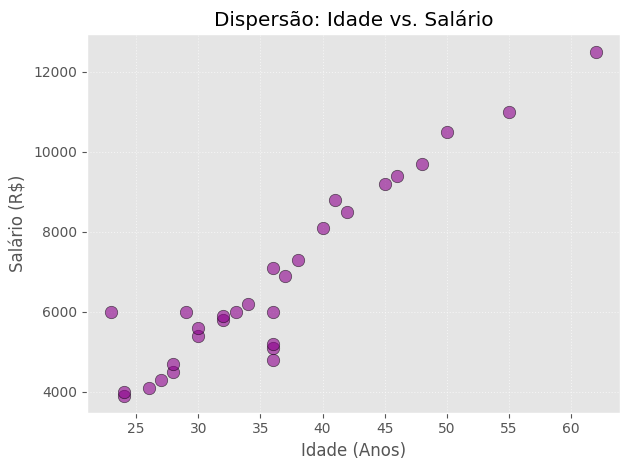

In [76]:
plt.Figure(figsize=(9,6))

# Criar dispersão (x = idade, y = salario)

plt.scatter(
  df_func['idade'],
  df_func['salario'],
  color='darkmagenta',
  s=80,  # tamanho dos pontos
  alpha=0.6, # transparência para ver as sobreposições
  edgecolors='black'
)

plt.title('Dispersão: Idade vs. Salário')
plt.xlabel('Idade (Anos)')
plt.ylabel('Salário (R$)')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
import os
os.makedirs('images', exist_ok=True)
plt.show()

#### Dashboard Demanadas

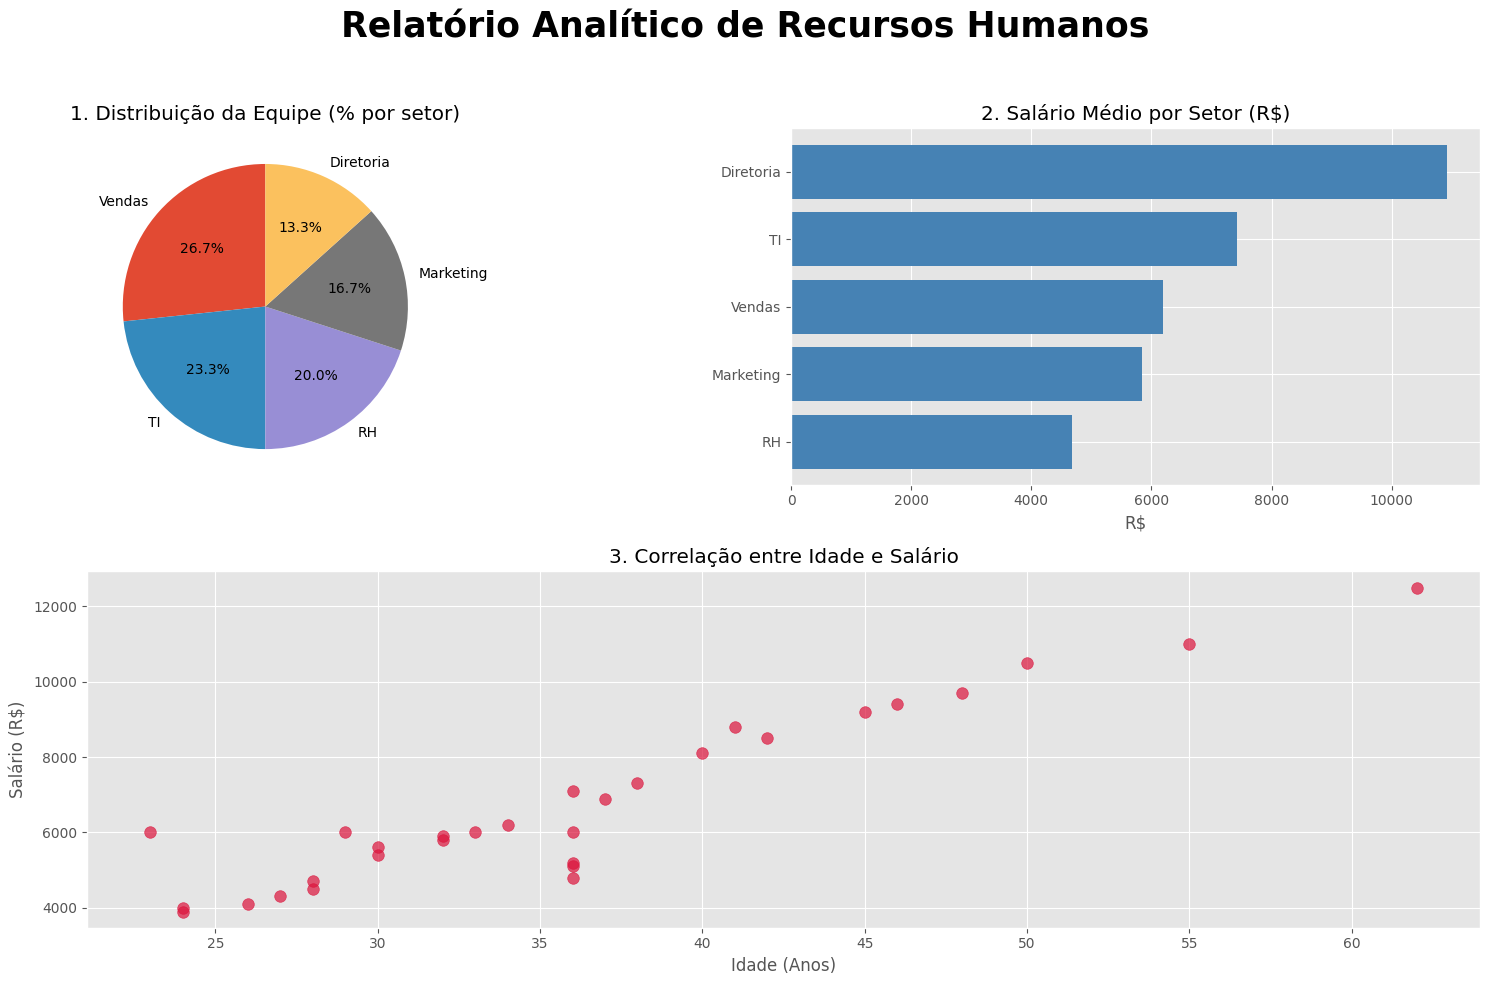

In [77]:
plt.style.use('ggplot')
fig = plt.figure(figsize=(15,10))
grid = fig.add_gridspec(2,2)

# Gráfico Pizza 
ax1 = fig.add_subplot(grid[0,0])
contagem = df_func['departamento'].value_counts()
ax1.pie(contagem.values, labels=contagem.index, autopct='%1.1f%%', startangle=90)
ax1.set_title('1. Distribuição da Equipe (% por setor)')
ax1.set_anchor('W')

# Gráfico de Barras
ax2 = fig.add_subplot(grid[0,1])
media_sal = df_func.groupby(['departamento'])['salario'].mean().sort_values()
ax2.barh(media_sal.index, media_sal.values, color='steelblue')
ax2.set_title('2. Salário Médio por Setor (R$)')
ax2.set_xlabel('R$')

# Dispersão

ax3 = fig.add_subplot(grid[1,:])
ax3.scatter(df_func['idade'], df_func['salario'], color='crimson', s=70, alpha=0.7)
ax3.set_title('3. Correlação entre Idade e Salário')
ax3.set_xlabel('Idade (Anos)')
ax3.set_ylabel('Salário (R$)')

# Dash
fig.suptitle('Relatório Analítico de Recursos Humanos', fontsize=25, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('relatorio_RH.png')
plt.show()

#### O Principal Insight: Déficit Orçamentário Estrutural em Todos os Setores

* Ao realizarmos a junção relacional das bases (`pd.merge()`) e multiplicarmos os salários mensais por 12 meses para apurar o custo fixo real de pessoal (`salario_anual`), revelou-se o dado mais crítico da empresa: 100% dos departamentos possuem uma folha salarial anual que supera o orçamento anual alocado.

* O orçamento anual cadastrado para toda a empresa foi dimensionado em R$ 1.250.000,00, porém a folha salarial real exigida para manter a equipe atual é de R$ 2.430.000,00. Isso gera um déficit global de R$ 1.180.000,00 (+94,4% acima do teto orçamentário).

### Pontos de Destaque:
*  **Maior Discrepância Relativa (Vendas e RH):** O setor de **Vendas** opera com quase **4x mais recursos do que o previsto** (396%), enquanto o **RH** opera com **mais de 3x seu orçamento** (337,2%).
* **Maior Custo Absoluto (TI e Vendas):** A **TI** representa a maior folha salarial da empresa (R$ 624 mil/ano), excedendo a meta orçamentária em R$ 324 mil.
* **Diretoria Próxima ao Equilíbrio:** A **Diretoria** é o único setor cujo orçamento inicial de R$ 500 mil ficou próximo de cobrir sua folha anual (diferença de apenas 4,9%).